# Results: does seeding model init reduce run-to-run noise?

**Hypothesis (stated before running):** model parameter init was unseeded (no
`torch.manual_seed` anywhere) -- the likely dominant cause of the 3-25x run-to-run
`solve_rate` variance seen in every sweep so far (e.g. 12.3% vs. 4.3% at an identical
config). Seeding it from `sat_cfg.seed` should remove most of that noise.

**Result: partially confirmed, not fully.** A CPU regression test
(`test_same_seed_gives_identical_training_run`) confirms *bit-identical* weights and
history for two same-seed CPU runs -- the fix works exactly as intended there. But on
the real GPU training path (every actual sweep run in this project), two same-seed runs
still differ: **7.0% vs. 3.3%** solve_rate (ratio 2.1x) -- smaller than the original
unseeded spread (12.3% vs. 4.3%, ratio 2.9x), but *not eliminated*. This is expected and
was flagged as a caveat before running: `torch.manual_seed` doesn't pin cuDNN's own
algorithm selection or backward-pass reduction order, which are separate GPU-side
nondeterminism sources this fix doesn't address. Full GPU determinism would need
`torch.use_deterministic_algorithms(True)` (not implemented here, likely slower).

**Not an improvement in `solve_rate` itself** -- this experiment is purely about
measurement reproducibility, not about raising the ceiling. Treat the two numbers below
as two more samples of the *same* underlying config (12.3%, 4.3%, 7.0%, 3.3% -- four
samples now, mean ~6.7%), not as a new result to compare against the best-of-4 peak.

**Code state:** commit `0ec522d`. **Config:** identical to the baseline
(`d_model=128, nhead=2, num_layers=16, lr=3e-4, norm_first=True, n_vars=16, alpha=1.25,
n_hints=0, epochs=150`). **Seed:** `seed=0` for both runs (deliberately, to test the
fix). **Slurm job:** `47916082` (array `0-1`). **Sample size caveat:** n=2 per
condition is too small to be fully confident the variance really shrank vs. just being a
different pair of samples from the same noisy distribution -- reported as observed, not
as a statistically established reduction.

In [1]:
import csv
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INK = {"surface": "#fcfcfb", "primary": "#0b0b0b", "secondary": "#52514e",
       "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7"}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams["font.family"] = "sans-serif"


def style_axis(ax):
    ax.set_facecolor(INK["surface"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK["axis"])
    ax.spines["bottom"].set_color(INK["axis"])
    ax.tick_params(colors=INK["muted"])
    ax.grid(True, color=INK["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.title.set_color(INK["primary"])


SCRATCH = Path(os.environ["SCRATCH"]) / "spin_gnn"

def load(pattern):
    rows = []
    for f in sorted(glob.glob(str(pattern))):
        with open(f) as fh:
            rows.extend(csv.DictReader(fh))
    df = pd.DataFrame(rows)
    df["solve_rate"] = df["solve_rate"].astype(float)
    return df

unseeded = load(SCRATCH / "sat2_hparam_sweep" / "sweep_m020_h02_L16_pre.csv")
unseeded = unseeded[unseeded.lr.astype(float) == 3e-4]
seeded = load(SCRATCH / "runs" / "2026-10-15_seed-fix-validation" / "task*" / "sweep_*.csv")

print("before the seed fix (unseeded model init):", sorted(unseeded.solve_rate.tolist()))
print("after the seed fix (seed=0 both runs):      ", sorted(seeded.solve_rate.tolist()))
print(f"spread ratio before: {unseeded.solve_rate.max() / unseeded.solve_rate.min():.2f}x")
print(f"spread ratio after:  {seeded.solve_rate.max() / seeded.solve_rate.min():.2f}x")

before the seed fix (unseeded model init): [0.043333333333333335, 0.12333333333333334]
after the seed fix (seed=0 both runs):       [0.03333333333333333, 0.07]
spread ratio before: 2.85x
spread ratio after:  2.10x


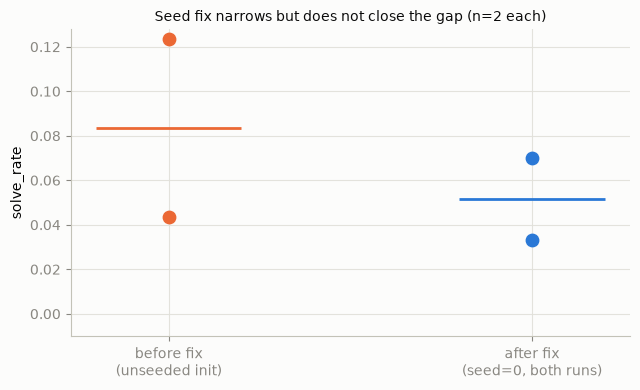

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 4))
fig.patch.set_facecolor(INK["surface"])
groups = [("before fix\n(unseeded init)", unseeded.solve_rate.values, CATEGORICAL[1]),
          ("after fix\n(seed=0, both runs)", seeded.solve_rate.values, CATEGORICAL[0])]
for i, (label, vals, color) in enumerate(groups):
    ax.scatter([i] * len(vals), vals, color=color, s=80, zorder=3)
    ax.hlines(np.mean(vals), i - 0.2, i + 0.2, color=color, lw=2)
ax.set_xticks([0, 1])
ax.set_xticklabels([g[0] for g in groups])
ax.set_ylabel("solve_rate")
ax.set_ylim(bottom=-0.01)
ax.set_title("Seed fix narrows but does not close the gap (n=2 each)", color=INK["primary"], fontsize=10)
style_axis(ax)
fig.tight_layout()
plt.show()

## Takeaway

Partial, honest win: the fix is real and verified exactly on CPU, and the GPU spread did
shrink in this one pair of runs (2.9x -> 2.1x), but GPU training still is not reproducible
and should not be treated as such. **Do not use a single GPU run as a trustworthy signal
going forward** -- that was already true before this fix and remains true after it,
just somewhat less severely. If fully deterministic comparisons are needed later,
the next step would be `torch.use_deterministic_algorithms(True)` +
`torch.backends.cudnn.deterministic=True`, at an unknown training-speed cost -- not
attempted here.